# Experiment 5 - Part 3: FAISS Indexes, Speed versus Accuracy, and Hybrid Search

**Course:** HAAI302COM - Artificial Intelligence Laboratory

In Part 2 we searched with one matrix product `Q @ D.T`. That is exact but its cost grows with the number of documents: ten million documents means ten million dot products per query. **FAISS** (Facebook AI Similarity Search) provides *indexes* that find *approximately* the nearest vectors much faster and with less memory. This notebook

1. builds FAISS indexes and checks they match the matrix product,
2. measures the speed / memory / accuracy trade-off of the main index types on a larger corpus,
3. checks that approximate search does not hurt retrieval quality on SciFact,
4. combines dense and TF-IDF search (**hybrid search**) and evaluates all methods together.

## 0. Setup

We reload the data and the saved document embeddings from Part 2 (`emb_minilm_title_text.npy`). If that file is missing, run notebook 02 first. Queries are encoded again; that takes seconds.

In [1]:
# !pip install -q faiss-cpu sentence-transformers scikit-learn datasets pandas matplotlib
import os, time, warnings
warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import faiss
pd.set_option("display.width", 170)

import ir_utils
data = ir_utils.load_scifact("test")
doc_texts = [t + ". " + x for t, x in zip(data["titles"], data["texts"])]
D = np.load("emb_minilm_title_text.npy").astype("float32")           # FAISS needs float32
print("faiss", faiss.__version__, "| documents:", D.shape, "| queries:", len(data["q_texts"]))

faiss 1.15.1 | documents: (5183, 384) | queries: 300


In [2]:
from sentence_transformers import SentenceTransformer
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
Q = model.encode(data["q_texts"], batch_size=64, normalize_embeddings=True, show_progress_bar=False).astype("float32")
print(Q.shape)

(300, 384)


## 1. The simplest index: `IndexFlatIP`

`IndexFlatIP` stores the vectors as they are and compares the query with every one (**IP** = inner product, which equals cosine for normalised vectors). It is exact, so it is our reference. The workflow for every FAISS index is the same: create, (train), `add` vectors, `search`.

In [3]:
flat = faiss.IndexFlatIP(D.shape[1])           # d = 384
flat.add(D)                                    # store the vectors; ids are 0..n-1 in insertion order
print("vectors in index:", flat.ntotal, "| dimension:", flat.d, "| needs training:", not flat.is_trained)
sims, ids = flat.search(Q, 100)                # for each query: top-100 similarities and document ids
print("result shapes:", sims.shape, ids.shape)

vectors in index: 5183 | dimension: 384 | needs training: False
result shapes: (300, 100) (300, 100)


In [4]:
manual = np.argsort(-(Q @ D.T), axis=1)[:, :100]
print("same ranking as the matrix product:", (manual[:, :10] == ids[:, :10]).all())
ir_utils.evaluate(ids, data["relevant"])

same ranking as the matrix product: True


recall@1      0.4846
recall@10     0.7883
recall@100    0.9250
mrr@10        0.6068
ndcg@10       0.6484
dtype: float64

**What to notice:** `search` returns two arrays: the similarity scores and the document ids (positions in the order we added them). The ranking matches the manual matrix product, and the retrieval metrics are identical to the dense results of Part 2. So the index is just a faster container, not a different method.

## 2. The scaling problem

With 5,183 documents everything is instant, so differences between indexes cannot be seen. To show what happens at scale, we build a **larger synthetic corpus**: 40 new vectors per real document, each a random *blend* of that document with another random document plus a little noise, giving about 207,000 vectors with graded similarities like a real collection (no two are near-duplicates). This is for timing only; relevance judgments only exist for the original documents.

In [5]:
rng = np.random.default_rng(0)
copies = 40
n = len(D)
first = np.repeat(np.arange(n), copies)                                    # each real document 40 times
second = rng.integers(0, n, size=n * copies)                               # a random partner document
w = rng.uniform(0.5, 1.0, size=(n * copies, 1)).astype("float32")          # how much of the first document to keep
big = w * D[first] + (1 - w) * D[second]
big += rng.standard_normal(big.shape).astype("float32") * (0.1 / np.sqrt(D.shape[1]))
big /= np.linalg.norm(big, axis=1, keepdims=True)                          # back to unit length
print("scaled corpus:", big.shape, "|", round(big.nbytes / 1e6), "MB as float32")

scaled corpus: (207320, 384) | 318 MB as float32


We time the exact search first and keep its answers as the **ground truth**. Timing uses one CPU thread (`omp_set_num_threads(1)`) so numbers are comparable per query; building uses all cores.

The accuracy measure for approximate search is **overlap@10**: of the 10 documents the exact search returns for a query, how many does the approximate index also return?

In [6]:
N_CPU = os.cpu_count()
faiss.omp_set_num_threads(1)

def timed_search(index, k=10, reps=3):
    best = 1e9
    for _ in range(reps):
        t0 = time.time(); _, I = index.search(Q, k); best = min(best, time.time() - t0)
    return I, best / len(Q) * 1000          # ids, milliseconds per query

def overlap(I, I_true):
    return float(np.mean([len(set(a) & set(b)) / len(b) for a, b in zip(I, I_true)]))

def size_mb(index):
    return len(faiss.serialize_index(index)) / 1e6

faiss.omp_set_num_threads(N_CPU)
flat_big = faiss.IndexFlatIP(big.shape[1]); flat_big.add(big)
faiss.omp_set_num_threads(1)
I_true, ms = timed_search(flat_big)
results = [{"index": "Flat (exact)", "params": "-", "build_s": 0.0, "size_MB": round(size_mb(flat_big)), "ms_per_query": round(ms, 2), "overlap@10": 1.0}]
pd.DataFrame(results)

,index,params,build_s,size_MB,ms_per_query,overlap@10
0,Flat (exact),-,0.0,318,23.87,1.0


**What to notice:** exact search over 207,000 vectors costs about 24 milliseconds per query on one thread, and the index is as large as the raw vectors (about 318 MB). Both grow linearly with the number of documents. At 100 million documents this would need 150 GB of RAM and seconds per query, which is the reason approximate indexes exist.

## 3. IVF: search only the nearest clusters

`IndexIVFFlat` first clusters the vectors with k-means into `nlist` cells (**training**). A query is compared only with the vectors in the `nprobe` closest cells instead of all of them. Two knobs:

| Parameter | Effect |
|---|---|
| `nlist` | number of clusters; more cells means fewer vectors per cell but a longer training |
| `nprobe` | how many cells to visit per query; the speed / accuracy dial (set at search time) |

In [7]:
def build_ivf(nlist):
    quant = faiss.IndexFlatIP(big.shape[1])                                  # finds the nearest cluster centres
    idx = faiss.IndexIVFFlat(quant, big.shape[1], nlist, faiss.METRIC_INNER_PRODUCT)
    faiss.omp_set_num_threads(N_CPU)
    t0 = time.time(); idx.train(big); idx.add(big); build = time.time() - t0
    faiss.omp_set_num_threads(1)
    return idx, build

ivf, ivf_build = build_ivf(256)
print("trained:", ivf.is_trained, "| vectors:", ivf.ntotal, "| cells:", ivf.nlist, "| build:", round(ivf_build, 1), "s")
sizes = np.array([ivf.invlists.list_size(i) for i in range(ivf.nlist)])        # vectors stored in each cell
print("vectors per cell: min", sizes.min(), "| mean", int(sizes.mean()), "| max", sizes.max())

trained: True | vectors: 207320 | cells: 256 | build: 3.8 s
vectors per cell: min 97 | mean 809 | max 2549


**What to notice:** the 207,000 vectors are spread over 256 cells with a mean of about 800 per cell, although the sizes are uneven (some cells hold several times the mean): clusters of text are not evenly populated. With `nprobe = 1` a query scans only about 800 vectors, a 250-fold reduction. Now we sweep `nprobe`.

In [8]:
ivf_rows = []
for nprobe in [1, 2, 4, 8, 16, 32, 64]:
    ivf.nprobe = nprobe
    I, ms = timed_search(ivf)
    ivf_rows.append({"index": "IVFFlat", "params": f"nlist=256, nprobe={nprobe}", "build_s": round(ivf_build, 1),
                     "size_MB": round(size_mb(ivf)), "ms_per_query": round(ms, 2), "overlap@10": round(overlap(I, I_true), 3)})
pd.DataFrame(ivf_rows)

,index,params,build_s,size_MB,ms_per_query,overlap@10
0,IVFFlat,"nlist=256, nprobe=1",3.8,320,0.14,0.599
1,IVFFlat,"nlist=256, nprobe=2",3.8,320,0.25,0.746
2,IVFFlat,"nlist=256, nprobe=4",3.8,320,0.49,0.835
3,IVFFlat,"nlist=256, nprobe=8",3.8,320,0.92,0.906
4,IVFFlat,"nlist=256, nprobe=16",3.8,320,1.79,0.946
5,IVFFlat,"nlist=256, nprobe=32",3.8,320,3.32,0.971
6,IVFFlat,"nlist=256, nprobe=64",3.8,320,6.56,0.995


**What to notice:** `nprobe=1` visits one cell out of 256 (about 0.4 percent of the data) and answers in 0.14 ms, 170 times faster than exact search, but finds only 60 percent of the true top 10. The time grows in step with `nprobe` (0.14, 0.27, 0.47, 0.88 ms ...) because every extra cell adds about 800 vectors to scan, while accuracy shows diminishing returns: `nprobe=16` gives 0.946 overlap at 1.7 ms (14 times faster than exact), and reaching 0.995 at `nprobe=64` costs 6.6 ms, only 3.6 times faster. The index size (320 MB) is the same as the flat index, since IVF reorganises the vectors rather than compressing them.

## 4. HNSW: a graph of neighbours

`IndexHNSWFlat` builds a layered graph where each vector links to `M` neighbours. A search starts at the top layer and walks greedily towards the query, like navigating a map from highways to local streets. It needs no training. Knobs:

| Parameter | Effect |
|---|---|
| `M` | links per node: more links mean better accuracy, more memory |
| `efConstruction` | search width while building the graph: higher means a better graph and slower build |
| `efSearch` | search width at query time: the speed / accuracy dial |

In [9]:
def build_hnsw(M, ef_construction=80):
    idx = faiss.IndexHNSWFlat(big.shape[1], M, faiss.METRIC_INNER_PRODUCT)
    idx.hnsw.efConstruction = ef_construction
    faiss.omp_set_num_threads(N_CPU)
    t0 = time.time(); idx.add(big); build = time.time() - t0
    faiss.omp_set_num_threads(1)
    return idx, build

hnsw, hnsw_build = build_hnsw(32)
print("HNSW M=32 built in", round(hnsw_build, 1), "s | size:", round(size_mb(hnsw)), "MB | levels:", hnsw.hnsw.max_level + 1)

HNSW M=32 built in 12.9 s | size: 375 MB | levels: 5


In [10]:
hnsw_rows = []
for ef in [8, 16, 32, 64, 128, 256]:
    hnsw.hnsw.efSearch = ef
    I, ms = timed_search(hnsw)
    hnsw_rows.append({"index": "HNSW", "params": f"M=32, efSearch={ef}", "build_s": round(hnsw_build, 1),
                      "size_MB": round(size_mb(hnsw)), "ms_per_query": round(ms, 2), "overlap@10": round(overlap(I, I_true), 3)})
pd.DataFrame(hnsw_rows)

,index,params,build_s,size_MB,ms_per_query,overlap@10
0,HNSW,"M=32, efSearch=8",12.9,375,0.05,0.699
1,HNSW,"M=32, efSearch=16",12.9,375,0.07,0.793
2,HNSW,"M=32, efSearch=32",12.9,375,0.10,0.888
3,HNSW,"M=32, efSearch=64",12.9,375,0.18,0.952
4,HNSW,"M=32, efSearch=128",12.9,375,0.33,0.974
5,HNSW,"M=32, efSearch=256",12.9,375,0.68,0.989


**What to notice:** at the same accuracy HNSW is far faster than IVF: `efSearch=64` gives 0.952 overlap in 0.18 ms, while IVF needed about 1.7 ms for 0.946, roughly ten times slower. At `efSearch=256` HNSW reaches 0.989 in 0.66 ms. The prices are memory and build time: the index is 375 MB, 18 percent larger than the raw vectors because of the graph links, and building took 12.8 s against 3.6 s for IVF. `efSearch` is set at query time, so one HNSW index can serve both a fast mode and a precise mode.

## 5. Compression: scalar quantisation and product quantisation

The indexes above still store every vector in full (4 bytes per number). Memory can be cut by compressing vectors:

- **Scalar quantiser (SQ8):** each number stored in 1 byte instead of 4 (4x smaller).
- **Product quantiser (PQ):** a vector of 384 numbers is cut into `m` pieces, each replaced by the id of its nearest centroid in a small codebook (one byte per piece). With `m = 48` a vector takes 48 bytes instead of 1,536 bytes (32x smaller). `IndexIVFPQ` combines this with IVF cells.

In [11]:
faiss.omp_set_num_threads(N_CPU)
t0 = time.time()
sq = faiss.IndexScalarQuantizer(big.shape[1], faiss.ScalarQuantizer.QT_8bit, faiss.METRIC_INNER_PRODUCT)
sq.train(big); sq.add(big); sq_build = time.time() - t0

t0 = time.time()
quant = faiss.IndexFlatIP(big.shape[1])
pq = faiss.IndexIVFPQ(quant, big.shape[1], 256, 48, 8, faiss.METRIC_INNER_PRODUCT)       # 256 cells, 48 pieces, 8 bits each
pq.train(big); pq.add(big); pq_build = time.time() - t0
faiss.omp_set_num_threads(1)

comp_rows = []
I, ms = timed_search(sq)
comp_rows.append({"index": "ScalarQuantizer", "params": "8 bit", "build_s": round(sq_build, 1), "size_MB": round(size_mb(sq)), "ms_per_query": round(ms, 2), "overlap@10": round(overlap(I, I_true), 3)})
for nprobe in [4, 16, 64]:
    pq.nprobe = nprobe
    I, ms = timed_search(pq)
    comp_rows.append({"index": "IVFPQ", "params": f"nlist=256, m=48, nprobe={nprobe}", "build_s": round(pq_build, 1), "size_MB": round(size_mb(pq)), "ms_per_query": round(ms, 2), "overlap@10": round(overlap(I, I_true), 3)})
pd.DataFrame(comp_rows)

,index,params,build_s,size_MB,ms_per_query,overlap@10
0,ScalarQuantizer,8 bit,0.3,80,33.13,0.972
1,IVFPQ,"nlist=256, m=48, nprobe=4",16.0,12,0.17,0.423
2,IVFPQ,"nlist=256, m=48, nprobe=16",16.0,12,0.56,0.463
3,IVFPQ,"nlist=256, m=48, nprobe=64",16.0,12,1.85,0.471


**What to notice:** the two compressions behave very differently. **SQ8** shrinks the index 4 times (80 MB) and keeps 0.972 overlap, but it is *slower* than exact search here (33 ms against 24 ms): it still scans every vector, and decoding bytes costs extra time. Use it to save memory, not time. **IVFPQ** shrinks the index 26 times (12 MB) and answers in 0.17 to 1.9 ms, but its overlap is only 0.42 to 0.47 and barely improves with `nprobe`. The limit is the quantisation error, not the search: 48 bytes cannot keep the fine ordering among close neighbours. The standard remedy is to over-fetch (for example top 100) and re-rank those candidates with the exact vectors, which FAISS offers as `IndexRefineFlat`.

## 6. The trade-off in one picture

Everything measured so far in one chart: for each configuration, the time per query against the accuracy.

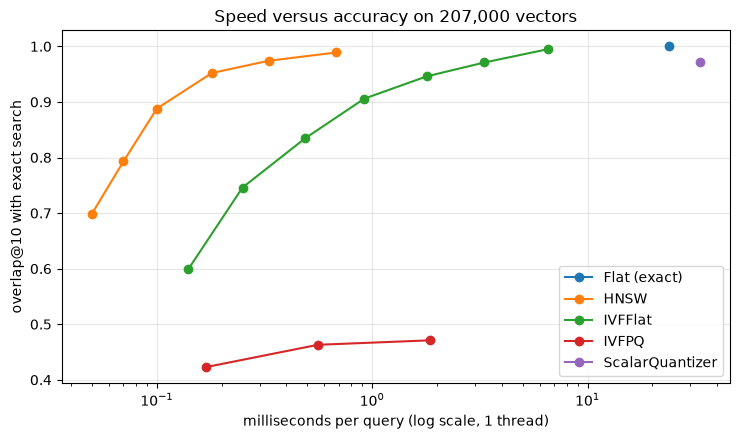

In [12]:
allr = pd.DataFrame(results + ivf_rows + hnsw_rows + comp_rows)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for name, g in allr.groupby("index"):
    ax.plot(g["ms_per_query"], g["overlap@10"], marker="o", label=name)
ax.set_xscale("log"); ax.set_xlabel("milliseconds per query (log scale, 1 thread)"); ax.set_ylabel("overlap@10 with exact search")
ax.set_title("Speed versus accuracy on 207,000 vectors"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

**What to notice:** a point further left is faster, higher is more accurate. HNSW is the upper-left frontier: 0.95 overlap at under 0.2 ms. The IVF curve lies to the right of it, so for equal accuracy it needs about ten times more time. Flat is the single point at 24 ms and overlap 1.0. SQ8 is accurate but slow, and IVFPQ is fast but its accuracy tops out below 0.5. There is no best index in general; the choice depends on whether memory, latency or accuracy is the binding constraint.

## 7. Does approximate search hurt retrieval quality?

Overlap@10 compares an index with *exact search*, but what we care about is whether the user still finds the relevant abstract. We rebuild three indexes on the real 5,183 documents and evaluate with the true relevance judgments.

In [13]:
def metrics_for(index, k=100):
    _, I = index.search(Q, k)
    return ir_utils.evaluate(I, data["relevant"])

real = {"Flat (exact)": flat}

hn = faiss.IndexHNSWFlat(D.shape[1], 32, faiss.METRIC_INNER_PRODUCT); hn.hnsw.efConstruction = 80; hn.add(D); hn.hnsw.efSearch = 64
real["HNSW M=32, efSearch=64"] = hn

iv = faiss.IndexIVFFlat(faiss.IndexFlatIP(D.shape[1]), D.shape[1], 64, faiss.METRIC_INNER_PRODUCT); iv.train(D); iv.add(D); iv.nprobe = 2
real["IVF nlist=64, nprobe=2"] = iv

iv8 = faiss.IndexIVFFlat(faiss.IndexFlatIP(D.shape[1]), D.shape[1], 64, faiss.METRIC_INNER_PRODUCT); iv8.train(D); iv8.add(D); iv8.nprobe = 8
real["IVF nlist=64, nprobe=8"] = iv8

pqi = faiss.IndexIVFPQ(faiss.IndexFlatIP(D.shape[1]), D.shape[1], 64, 48, 6, faiss.METRIC_INNER_PRODUCT); pqi.train(D); pqi.add(D); pqi.nprobe = 8
real["IVFPQ nlist=64, m=48, 6 bit, nprobe=8"] = pqi

real_df = pd.DataFrame({name: metrics_for(ix) for name, ix in real.items()}).T
real_df["size_MB"] = [round(size_mb(ix), 1) for ix in real.values()]
real_df

,recall@1,recall@10,recall@100,mrr@10,ndcg@10,size_MB
Flat (exact),0.4846,0.7883,0.9250,0.6068,0.6484,8.0
"HNSW M=32, efSearch=64",0.4812,0.7850,0.9267,0.6035,0.6451,9.4
"IVF nlist=64, nprobe=2",0.3479,0.5510,0.6187,0.4362,0.4598,8.1
"IVF nlist=64, nprobe=8",0.4529,0.7160,0.8370,0.5599,0.5951,8.1
"IVFPQ nlist=64, m=48, 6 bit, nprobe=8",0.3798,0.6776,0.8387,0.4953,0.5321,0.4


**What to notice:** this table uses real relevance judgments, and it corrects a possible wrong impression from the synthetic benchmark. HNSW (`efSearch=64`) is practically lossless: nDCG@10 0.645 against 0.648 for exact search, for 1.4 MB more memory. The IVF settings, however, **hurt**: `nprobe=2` of 64 cells drops nDCG@10 to 0.460 and even `nprobe=8` only recovers to 0.595. Short claims lie in different regions of the vector space than the abstracts they should find, so the cells nearest to a query often do not contain its answer. IVFPQ (6-bit codes here, because 8-bit codebooks need more training points than this corpus has) is 20 times smaller (0.4 MB) and loses 0.12 nDCG. Two lessons: tune the index on your own queries and relevance labels, and for a corpus of only 5,000 documents just use the exact flat index, which is instant.

## 8. Hybrid search: dense plus keyword

Dense search handles paraphrase; keyword search is strong when the query contains rare exact terms (gene names, drug names, numbers). Combining them is common in production RAG. Two fusion methods:

- **Reciprocal Rank Fusion (RRF):** each method contributes `1 / (60 + rank)` for every document; the contributions are summed. It uses only ranks, so the different score scales do not matter.
- **Weighted score fusion:** min-max scale each method's scores to 0 to 1 and compute `alpha x dense + (1 - alpha) x tfidf`. This needs the weight `alpha`.

To choose `alpha` honestly we tune it on the **training** queries of SciFact (a separate set of claims) and then report results on the test queries, which are not touched during tuning.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

vec = TfidfVectorizer(sublinear_tf=True, stop_words="english", ngram_range=(1, 2))
X = vec.fit_transform(doc_texts)

def score_matrices(texts):
    q_emb = model.encode(texts, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    return q_emb @ D.T, linear_kernel(vec.transform(texts), X)           # dense cosine, tf-idf cosine

dense_te, tfidf_te = score_matrices(data["q_texts"])
train = ir_utils.load_scifact("train")
dense_tr, tfidf_tr = score_matrices(train["q_texts"])
print("test queries:", len(data["q_texts"]), "| train queries (for tuning only):", len(train["q_texts"]))

test queries: 300 | train queries (for tuning only): 809


In [15]:
def minmax(S):
    lo, hi = S.min(axis=1, keepdims=True), S.max(axis=1, keepdims=True)
    return (S - lo) / (hi - lo + 1e-9)

def weighted(dense_s, tfidf_s, alpha):
    return alpha * minmax(dense_s) + (1 - alpha) * minmax(tfidf_s)

def rrf(dense_s, tfidf_s, k=60):
    out = np.zeros_like(dense_s)
    for S in (dense_s, tfidf_s):
        rank = np.argsort(np.argsort(-S, axis=1), axis=1) + 1            # rank of every document, 1 = best
        out += 1.0 / (k + rank)
    return out

def to_ranked(S):
    return np.argsort(-S, axis=1)[:, :100]

alphas = np.round(np.arange(0, 1.01, 0.1), 1)
sweep = pd.DataFrame({"train_ndcg@10": [ir_utils.evaluate(to_ranked(weighted(dense_tr, tfidf_tr, a)), train["relevant"])["ndcg@10"] for a in alphas],
                      "test_ndcg@10": [ir_utils.evaluate(to_ranked(weighted(dense_te, tfidf_te, a)), data["relevant"])["ndcg@10"] for a in alphas]}, index=alphas)
sweep.index.name = "alpha (1 = dense only, 0 = tf-idf only)"
best_alpha = float(sweep["train_ndcg@10"].idxmax())
print("alpha chosen on the TRAIN queries:", best_alpha)
sweep

alpha chosen on the TRAIN queries: 0.7


,train_ndcg@10,test_ndcg@10
"alpha (1 = dense only, 0 = tf-idf only)",,
0.0,0.6341,0.6418
0.1,0.6442,0.6585
0.2,0.6550,0.6675
0.3,0.6705,0.6825
0.4,0.6829,0.6916
0.5,0.6970,0.7009
0.6,0.7058,0.7109
0.7,0.7181,0.7154
0.8,0.7164,0.7127


**What to notice:** dense-only (`alpha = 1`) scores 0.648 and TF-IDF-only (`alpha = 0`) 0.642, but every mixture in between is better, peaking near `alpha = 0.7` on the training queries (0.718). The test queries, which were not used for tuning, peak at the same place (0.715), so the weight transfers and we are not fooling ourselves. The curve is flat between 0.6 and 0.8, which means the exact value is not critical: any reasonable blend that is mostly dense with a solid keyword share works.

## 9. Final comparison

In [16]:
final = {
    "TF-IDF (best settings)": to_ranked(tfidf_te),
    "Dense MiniLM (exact)": to_ranked(dense_te),
    "Dense via HNSW index": hn.search(Q, 100)[1],
    f"Hybrid weighted (alpha={best_alpha})": to_ranked(weighted(dense_te, tfidf_te, best_alpha)),
    "Hybrid RRF (k=60)": to_ranked(rrf(dense_te, tfidf_te)),
}
final_df = pd.DataFrame({k: ir_utils.evaluate(v, data["relevant"]) for k, v in final.items()}).T
final_df

,recall@1,recall@10,recall@100,mrr@10,ndcg@10
TF-IDF (best settings),0.4850,0.7790,0.8916,0.6047,0.6418
Dense MiniLM (exact),0.4846,0.7883,0.9250,0.6068,0.6484
Dense via HNSW index,0.4812,0.7850,0.9267,0.6035,0.6451
Hybrid weighted (alpha=0.7),0.5584,0.8496,0.9617,0.6768,0.7154
Hybrid RRF (k=60),0.5280,0.8356,0.9617,0.6490,0.6900


**What to notice:** hybrid weighted fusion raises nDCG@10 from 0.648 (dense) to 0.715, recall@1 from 0.485 to 0.558 and recall@100 from 0.925 to 0.962. This is a larger gain than any of the other changes in this experiment, because the two methods fail on different queries (Part 2: 37 queries only dense finds, 29 only TF-IDF). RRF needs no tuning and already gets 0.690; the tuned weight adds another 0.025. Dense search through the HNSW index matches exact dense search (0.645 against 0.648), so approximation is not what limits quality; the representation is. Caveats: the weight was tuned on SciFact, whose claims are full of exact technical terms, so a different dataset may prefer a different `alpha`; and hybrid search runs two retrievals per query.

## Summary

| Question | Answer from our measurements |
|---|---|
| When is brute-force search enough? | Up to tens of thousands of vectors: exact and fast (Section 1) |
| How do I speed up search at scale? | IVF (visit a few clusters) or HNSW (graph walk); tune `nprobe` / `efSearch` (Sections 3 to 4) |
| How do I cut memory? | SQ8 (4x) or product quantisation (up to 32x), paid for in accuracy (Section 5) |
| Does approximation hurt relevance? | Check on your own data; here it barely did (Section 7) |
| Dense or keyword? | Dense usually wins, hybrid fusion can add a little and protects against exact-term queries (Sections 8 and 9) |

**Experiment 5 complete.** You built a TF-IDF baseline (Part 1), a semantic search engine (Part 2) and compared FAISS indexes and hybrid search (Part 3), always measured with Recall@k, MRR and nDCG.